<a href="https://colab.research.google.com/github/vihangasathsara-75/cm2604-cw-telco-churn-prediction/blob/main/notebooks/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/vihangasathsara-75/cm2604-cw-telco-churn-prediction/refs/heads/main/data/raw/Telco-Churn.csv"
df = pd.read_csv(url)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [3]:
# TotalCharges has blank spaces, so pandas read it as text
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print(df.isnull().sum())
df[df["TotalCharges"].isnull()][["customerID", "tenure", "TotalCharges"]]

df.info()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService    

In [4]:
print("Duplicate rows:", df.duplicated().sum())
print("customerID unique:", df["customerID"].is_unique)

print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True))

Duplicate rows: 0
customerID unique: True
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


In [5]:
missing = df[df["TotalCharges"].isnull()]
print(missing[["customerID", "tenure", "MonthlyCharges", "Churn"]])
print("Unique tenure values:", missing["tenure"].unique())

      customerID  tenure  MonthlyCharges Churn
488   4472-LVYGI       0           52.55    No
753   3115-CZMZD       0           20.25    No
936   5709-LVOEQ       0           80.85    No
1082  4367-NUYAO       0           25.75    No
1340  1371-DWPAZ       0           56.05    No
3331  7644-OMVMY       0           19.85    No
3826  3213-VVOLG       0           25.35    No
4380  2520-SGTTA       0           20.00    No
5218  2923-ARZLG       0           19.70    No
6670  4075-WKNIU       0           73.35    No
6754  2775-SEFEE       0           61.90    No
Unique tenure values: [0]


In [6]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print(df.shape)
print(df["TotalCharges"].isnull().sum())

(7043, 21)
0


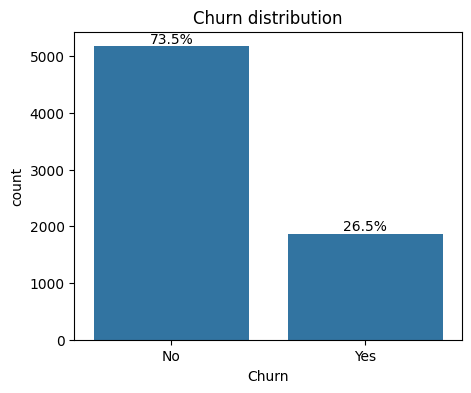

In [7]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(x="Churn", data=df)
ax.set_title("Churn distribution")

for p in ax.patches:
    pct = p.get_height() / len(df) * 100
    ax.annotate(
        f"{pct:.1f}%",
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center",
        va="bottom",
    )
plt.show()

In [8]:
numerical_cols = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical columns:")
print(numerical_cols)

df[numerical_cols].describe()

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [10]:
numerical_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

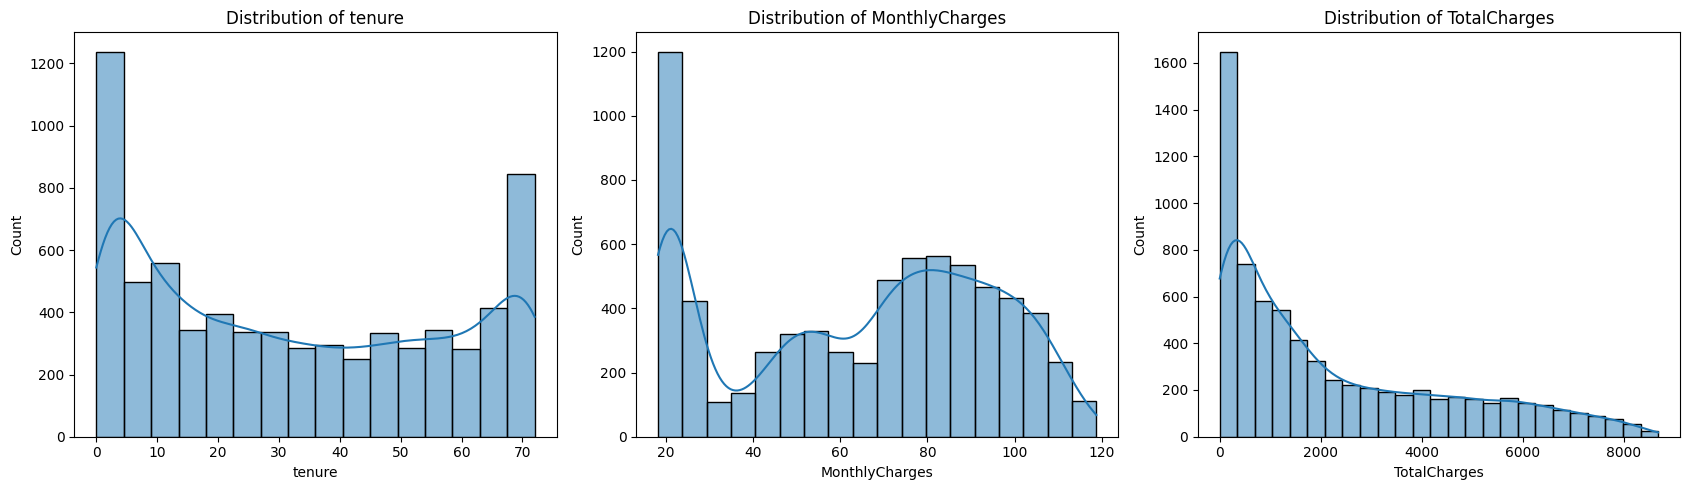

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for i, col in enumerate(numerical_cols):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

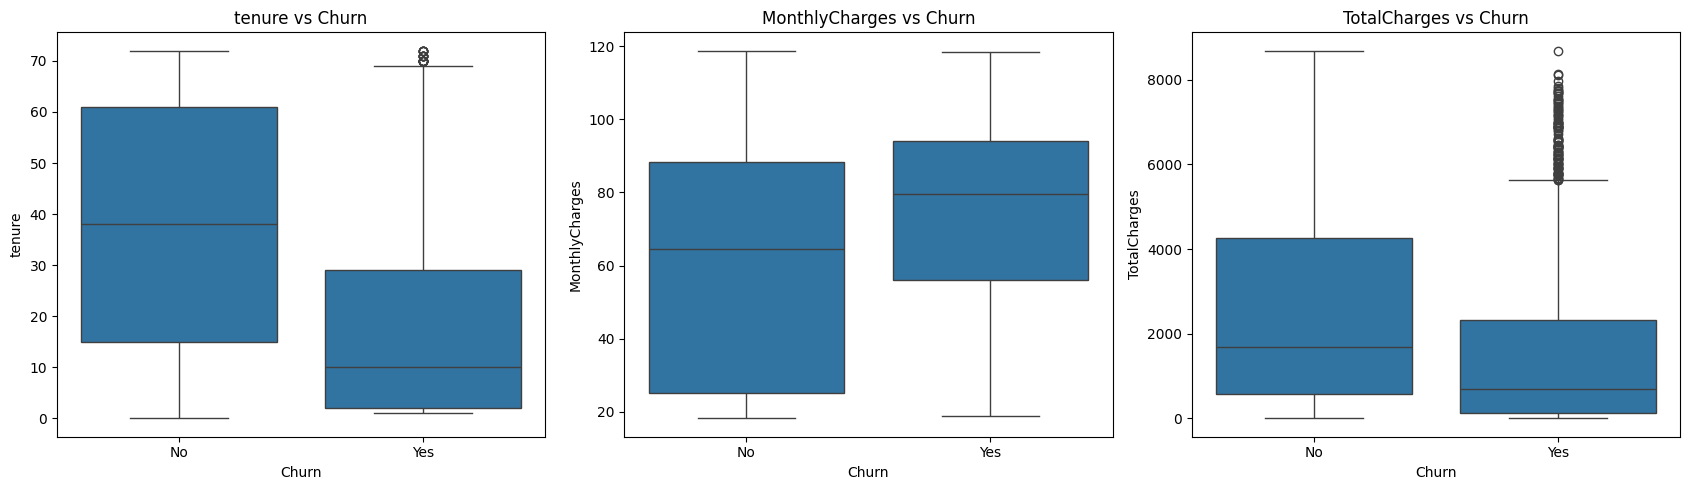

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for i, col in enumerate(numerical_cols):
    sns.boxplot(
        data=df,
        x="Churn",
        y=col,
        ax=axes[i]
    )
    axes[i].set_title(f"{col} vs Churn")

plt.tight_layout()
plt.show()

In [13]:
categorical_cols = df.select_dtypes(
    include=["object"]
).columns.tolist()

categorical_cols.remove("customerID")
categorical_cols.remove("Churn")

print("Categorical columns:")
print(categorical_cols)

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


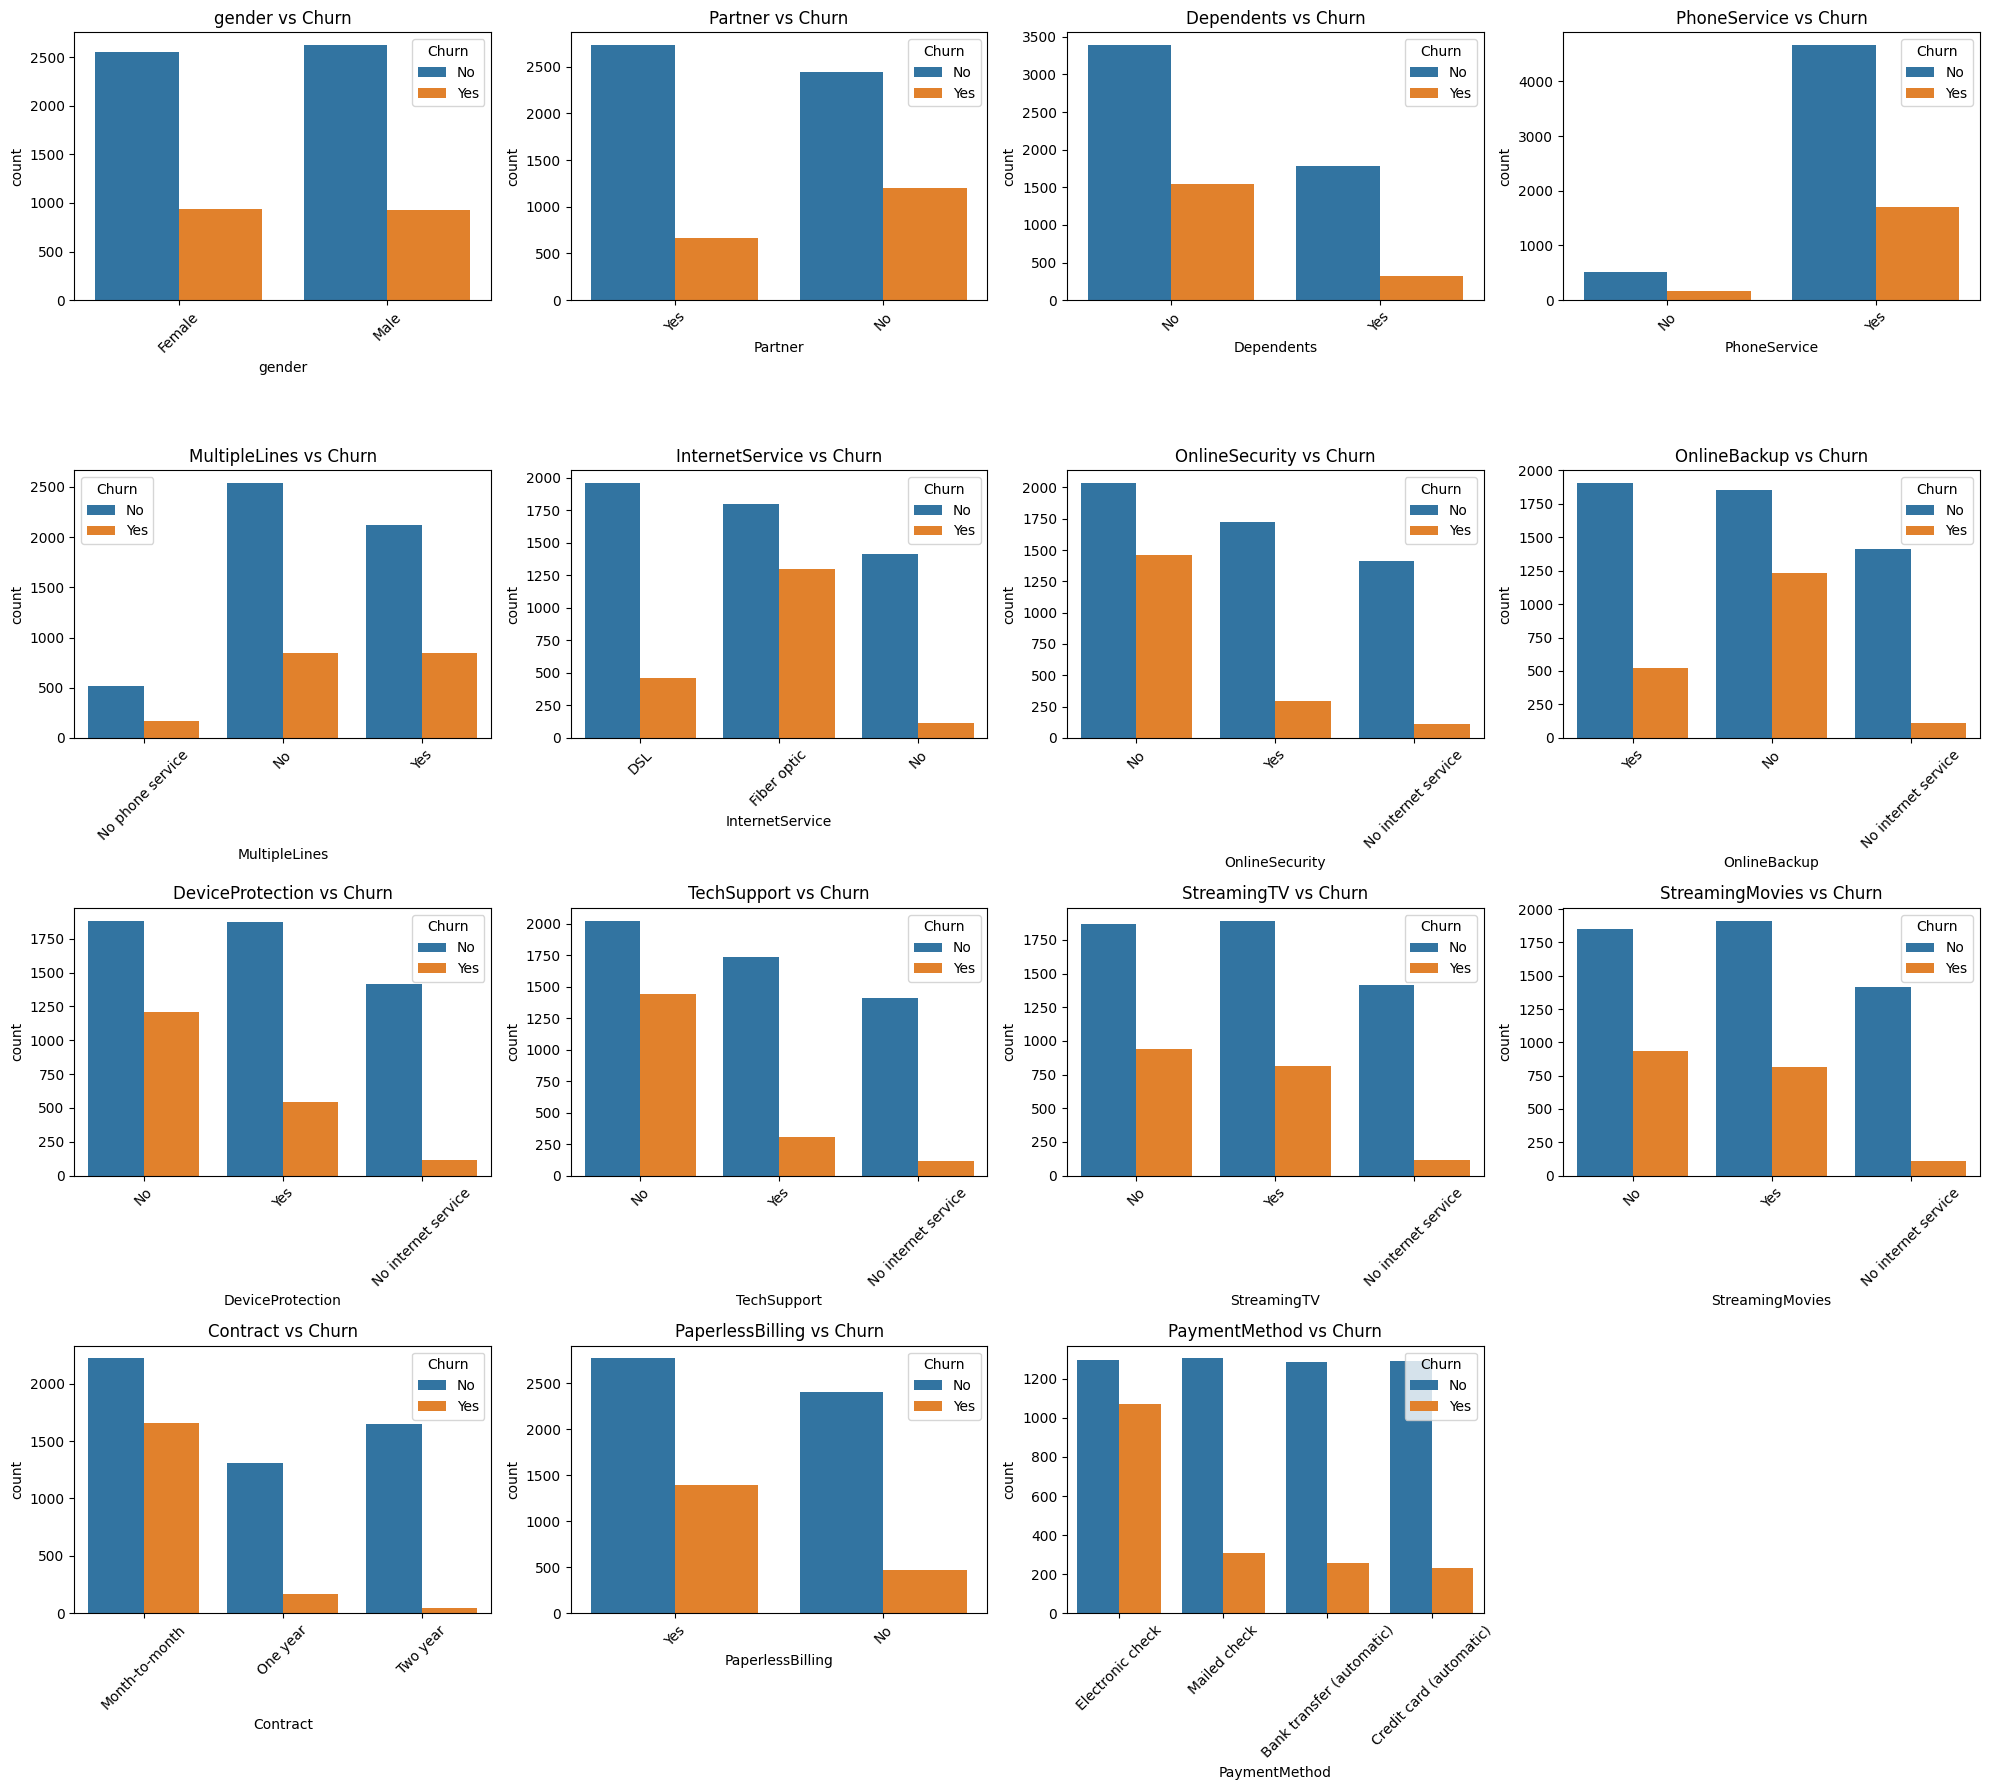

In [14]:
fig, axes = plt.subplots(4, 4, figsize=(20, 18))

axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(
        data=df,
        x=col,
        hue="Churn",
        ax=axes[i]
    )

    axes[i].set_title(f"{col} vs Churn")
    axes[i].tick_params(axis="x", rotation=45)

for j in range(len(categorical_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()